# 1D application: Sine function

In [1]:
import os
import sys
sys.path.append(os.path.abspath('../python_files'))
from utils import *
from Gaussian_Process import *
from Multifidelity_GP_AR1 import *

import matplotlib.pyplot as plt
from scipy.stats import qmc
from copy import deepcopy
import pickle
import pyDOE3
import time

In [2]:
notebook_dir = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
plot_dir = os.path.abspath(os.path.join(notebook_dir, '../plots'))
data_dir = os.path.abspath(os.path.join(notebook_dir, '../data'))

In [ ]:
n_seed = 0
n_seed_MF = 0
np.random.seed(n_seed)
LFcode = Sine_LF
HFcode = Sine_HF
noise_L = 0.3**2
noise_H = 0.1**2
n_starts = 20
n_cores = 1
D = 1
jitter = 1e-10
EM_iter = 200
EM_tol = 1e-10
N_test = 10**4
X_test = np.linspace(0., 2., N_test).reshape(-1, 1)

save_computations = False  # change to True if the folder 'Sine_runs' is incomplete
namefile_metrics = 'Sine_metrics.pkl'
path_metrics = os.path.join(data_dir, namefile_metrics)
save_metrics = False  # change to True if the file 'Sine_metrics.pkl' is not available or for re-computing the metrics
study_seed = 0   # replication k uses the generator np.random.default_rng(study_seed + k)

In [4]:
n_seed = 0
n_seed_MF = 0
np.random.seed(n_seed)
listN_H = [5, 10, 20]
listN_L = [100, 500, 1000]   
numH = len(listN_H)
numL = len(listN_L)
num_rep = 100
nrec_jitter = 1e-5

error_vals_mf, error_vals_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))
error_vals_hf = np.zeros((numH, num_rep))
IAE_ci_mf, IAE_ci_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))
IAE_pi_mf, IAE_pi_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))
IAE_ci_hf = np.zeros((numH, num_rep))
IAE_pi_hf = np.zeros((numH, num_rep))
WCI_mf, WCI_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))
WCI_hf = np.zeros((numH, num_rep))
WPI_mf, WPI_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))
WPI_hf = np.zeros((numH, num_rep))
time_mf, time_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))          # wall-clock time (time.time)
cpu_time_mf, cpu_time_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))  # CPU time (time.process_time)
NV_mf, NV_ko = np.zeros((numL, numH, num_rep)), np.zeros((numL, numH, num_rep))  # estimated HF noise variance
NV_hf = np.zeros((numH, num_rep))

In [5]:
# Random draws: ONE generator per replication, rng = np.random.default_rng(study_seed + k), and EVERYTHING random in
# replication k (designs, noises, multi-start seeds) is drawn one after the other from this generator. Two draws from the
# same generator never repeat each other, and two replications use two different generators.
def new_seed(rng):
    """ Integer seed (for pyDOE3 / qmc and the multi-starts of fit), drawn from the generator rng. """
    return int(rng.integers(2**32))

def generate_data(k):
    """ All the random draws of replication k. Returns data[('H', j)] = (X_H, z_H, seed_design, seed_optim)
        and data[('L', i, j)] = (X_L, z_L, seed_design, seed_optim). The HF data of (k, j) are shared by the 3 values of N_L. """
    rng = np.random.default_rng(study_seed + k)
    data = {}
    for j, N_H in enumerate(listN_H):
        seed_XH = new_seed(rng)
        X_H = 2*qmc.LatinHypercube(d=D, rng=seed_XH).random(n=N_H)
        z_H = HFcode(X_H) + np.sqrt(noise_H) * rng.standard_normal((N_H, 1))
        data[('H', j)] = (X_H, z_H, seed_XH, new_seed(rng))
        for i, N_L in enumerate(listN_L):
            seed_XL = new_seed(rng)
            X_L = 2*qmc.LatinHypercube(d=D, rng=seed_XL).random(n=N_L)
            z_L = LFcode(X_L) + np.sqrt(noise_L) * rng.standard_normal((N_L, 1))
            data[('L', i, j)] = (X_L, z_L, seed_XL, new_seed(rng))
    return data

In [6]:
def check_random_draws(reps=None):
    """ Checks the random draws of the replications:
    all seeds distinct, no noise value repeated, no design point repeated, standardized noise. """
    reps = range(num_rep) if reps is None else reps
    seeds, noise, points = [], [], []
    for k in reps:
        for key, (X, z, seed_X, seed_opt) in generate_data(k).items():
            code, sd = (HFcode, np.sqrt(noise_H)) if key[0] == 'H' else (LFcode, np.sqrt(noise_L))
            noise.append(((z - code(X)) / sd).ravel())
            points.append(X)
            seeds += [seed_X, seed_opt]
    e = np.concatenate(noise)
    P = np.concatenate(points)
    print(f"{len(reps)} replications, {len(noise)} noise realisations, {len(points)} input designs")
    print(f" distincts seeds: {len(set(seeds))} / {len(seeds)}")
    print(f" repeated noise values : {e.size - np.unique(e).size} / {e.size}")
    print(f" repeated design points : {P.shape[0] - np.unique(P, axis=0).shape[0]} / {P.shape[0]}")
    print(f" standardized noise : mean = {e.mean():.4f}, sd = {e.std():.4f}")
check_random_draws()

100 replications, 1200 noise realisations, 1200 input designs
 distincts seeds: 2400 / 2400
 repeated noise values : 0 / 483500
 repeated design points : 0 / 483500
 standardized noise : mean = 0.0011, sd = 0.9989


In [7]:
# ~ 45h in total (~27 min per replication) : one file per replication.
runs_dir = os.path.join(data_dir, 'Sine_runs')  
os.makedirs(runs_dir, exist_ok=True)
n_this_session = None     # number of replications in this session (None : all)
max_hours = 72.           # optional : time budget
path_durations = os.path.join(runs_dir, 'rep_durations.pkl')   # wall-clock time of the different replications

def rep_path(k):
    return os.path.join(runs_dir, f'Sine_rep{k:03d}.pkl')

def run_replication(k):
    """ Trains all models of replication k on the data of generate_data(k). """
    data = generate_data(k)
    Res_k = {}
    for j in range(numH):
        # HF data and parameters
        N_H = listN_H[j]
        X_H, z_H, seed_XH, seed_optH = data[('H', j)]
        theta_H = np.ones(D)
        zeta_H = np.array([0.])
        beta_H = np.array([[0.]])
        sigma2_H = 1.
        # Train HF-only-GP
        mbasis_Hsk = Polynomial_basis(None, 1)
        kernel_Hsk = RBF_kernel(theta_H)
        eta_fnHsk = Homoscedastic(params=zeta_H)
        gp_Hsk = GPR(mbasis_Hsk, kernel_Hsk, X_H, z_H, noise='opt', eta_fn=eta_fnHsk)
        best, nlml_value = gp_Hsk.fit(n_starts=n_starts, n_cores=n_cores, jitter=jitter, rng_seed=seed_optH, verbose=False)
        for i in range(numL):
            N_L = listN_L[i]
            X_L, z_L, seed_XL, seed_opt = data[('L', i, j)]
            theta_L = np.ones(D)
            zeta_L = np.array([0.])
            ### Recursive MF-GP ###
            mbasis_L = Polynomial_basis(None, 1)
            kernel_L = RBF_kernel(theta_L)
            eta_fnL = Homoscedastic(params=zeta_L)
            gp_L = GPR(mbasis_L, kernel_L, X_L, z_L, noise='opt', eta_fn=eta_fnL)
            w1, c1 = time.time(), time.process_time()
            best, nlml_value = gp_L.fit(n_starts=n_starts, n_cores=n_cores, jitter=jitter, rng_seed=seed_opt, verbose=False)
            w2, c2 = time.time(), time.process_time()
            beta_rho = np.array([[1.]])
            theta_H = np.ones(D)
            zeta_H = np.array([0.])
            beta_H = np.array([[0.]])
            sigma2_H = 1.
            mbasis_H = Polynomial_basis(beta_H, 1)
            scale = Polynomial_basis(beta_rho, 1)
            kernel_H = RBF_kernel(theta_H, sigma2_H)
            eta_fnH = Homoscedastic(params=zeta_H)
            gp_H = GPR(mbasis_H, kernel_H, X_H, z_H, noise='opt', eta_fn=eta_fnH)
            MF_gp = Multifi_GP_AR1(gp_L, gp_H, scale)
            w3, c3 = time.time(), time.process_time()
            best, nll = MF_gp.fit(EM_iter=EM_iter, n_starts=n_starts, n_cores=n_cores,
                                  jitter=jitter, rng_seed=seed_opt, verbose=False, tol=EM_tol)
            w4, c4 = time.time(), time.process_time()
            ### Non-recursive MF-GP ###
            theta_L = np.ones(D)
            zeta_L = np.array([0.])
            mbasis_L = Constant_basis(None)
            sigma2_L = 1.
            kernel_L = RBF_kernel(theta_L, sigma2_L)
            eta_fnL = Homoscedastic(params=zeta_L)
            gp_LKO = GPR(mbasis_L, kernel_L, X_L, z_L, noise='opt', eta_fn=eta_fnL)
            theta_H = np.ones(D)
            zeta_H = np.array([0.])
            beta_rho = np.array([[1.]])
            mbasis_H = Polynomial_basis(None, 1)
            scale = Polynomial_basis(beta_rho, 1)
            kernel_H = RBF_kernel(theta_H, sigma2_H)
            eta_fnH = Homoscedastic(params=zeta_H)
            gp_HKO = GPR(mbasis_H, kernel_H, X_H, z_H, noise='opt', eta_fn=eta_fnH)
            MF_gpKO = Multifi_GP_AR1_KO(gp_LKO, gp_HKO, scale)
            MF_gpKO.bounds[-1] = (-10., 10.)
            w5, c5 = time.time(), time.process_time()
            best, nlml_value = MF_gpKO.fit(n_starts=n_starts, n_cores=n_cores, jitter=nrec_jitter, rng_seed=seed_opt, verbose=False)
            w6, c6 = time.time(), time.process_time()
            Classes = MF_gp, MF_gpKO, gp_Hsk
            Data = X_L, z_L, X_H, z_H
            Res_k[(i, j, k)] = {'Data' : Data, 'Class' : Classes,
                                'Seeds' : {'generator': study_seed + k, 'X_H': seed_XH, 'opt_HF_only': seed_optH, 'X_L': seed_XL, 'opt_MF': seed_opt},
                                'Time' : ((w4-w3)+(w2-w1), w6-w5),         # wall-clock (rec, nrec)
                                'CPU_Time' : ((c4-c3)+(c2-c1), c6-c5),     # CPU time (rec, nrec)
                                'Time_split_rec': (w2-w1, w4-w3),          # wall-clock (LF fit, EM) of the R-MFGP
                                'CPU_split_rec': (c2-c1, c4-c3)}           # CPU time (LF fit, EM) of the R-MFGP
    return Res_k

def load_durations():
    if os.path.exists(path_durations):
        with open(path_durations, 'rb') as f:
            return pickle.load(f)
    return {}

def fmt(sec):
    return f"{int(sec // 3600)} h {int(sec % 3600 // 60):02d} min"

if save_computations:
    todo = [k for k in range(num_rep) if not os.path.exists(rep_path(k))]
    if n_this_session is not None:
        todo = todo[:n_this_session]
    rep_durations = load_durations()
    n_done = sum(os.path.exists(rep_path(k)) for k in range(num_rep))
    print(f"{n_done}/{num_rep} replications done,  this session: {len(todo)} replication(s)"
          + (f" ({todo[0]+1} to {todo[-1]+1})" if todo else ""))
    if rep_durations and todo:
        d_med = np.median(list(rep_durations.values()))
        est = len(todo) * d_med
        print(f"Estimated time : {fmt(est)} ({d_med/60:.1f} min per replication, median on {len(rep_durations)}).")
    elif todo:
        print("Time estimation available after the first replication.")
    t_session, durations = time.time(), []
    for n, k in enumerate(todo):
        if max_hours is not None and durations and (time.time() - t_session + np.mean(durations)) > max_hours * 3600:
            print(f"Time budget of {max_hours} h achieved: stop before replication {k+1}")
            break
        t0 = time.time()
        Res_k = run_replication(k)
        tmp = rep_path(k) + '.tmp'
        with open(tmp, 'wb') as f:      # temporary file
            pickle.dump(Res_k, f)     
        os.replace(tmp, rep_path(k))
        durations.append(time.time() - t0)
        rep_durations[k] = durations[-1]
        with open(path_durations, 'wb') as f:
            pickle.dump(rep_durations, f)
        left = (len(todo) - n - 1) * np.median(list(rep_durations.values()))
        print(f"rep {k+1}/{num_rep} : {durations[-1]/60:.1f} min" + (f" | {len(todo)-n-1} replication(s) remain, ~{fmt(left)}"
                if n < len(todo) - 1 else " | Session finished"))

done = [k for k in range(num_rep) if os.path.exists(rep_path(k))]
if len(done) == num_rep:
    print(f"{num_rep} seeds are done")
else:
    print(f"{len(done)}/{num_rep} seeds done")

76/100 replications done,  this session: 24 replication(s) (77 to 100)
Estimated time : 11 h 08 min (27.9 min per replication, median on 76).
rep 77/100 : 28.1 min | 23 replication(s) remain, ~10 h 40 min
rep 78/100 : 27.6 min | 22 replication(s) remain, ~10 h 12 min
rep 79/100 : 28.7 min | 21 replication(s) remain, ~9 h 45 min
rep 80/100 : 28.9 min | 20 replication(s) remain, ~9 h 17 min
rep 81/100 : 29.4 min | 19 replication(s) remain, ~8 h 50 min
rep 82/100 : 28.0 min | 18 replication(s) remain, ~8 h 23 min
rep 83/100 : 28.1 min | 17 replication(s) remain, ~7 h 56 min
rep 84/100 : 27.3 min | 16 replication(s) remain, ~7 h 27 min
rep 85/100 : 29.6 min | 15 replication(s) remain, ~7 h 00 min
rep 86/100 : 27.2 min | 14 replication(s) remain, ~6 h 31 min
rep 87/100 : 27.4 min | 13 replication(s) remain, ~6 h 03 min
rep 88/100 : 24.3 min | 12 replication(s) remain, ~5 h 34 min
rep 89/100 : 27.4 min | 11 replication(s) remain, ~5 h 06 min
rep 90/100 : 26.7 min | 10 replication(s) remain, 

In [8]:
# ~ 13min30s
n_seed = 0
n_seed_MF = 0
np.random.seed(n_seed)

if save_metrics:
    missing = [k for k in range(num_rep) if not os.path.exists(rep_path(k))]
    assert not missing, f"Missing seeds: {missing}"
    EM_traces = {}   # log-likelihood along EM iterations of each recursive MF-GP, (i, j, k) -> array
    for k in tqdm(range(num_rep), desc='Compute metrics'):
        with open(rep_path(k), 'rb') as f:
            Res_k = pickle.load(f)   # one replication in memory at a time
        for j in range(numH):
            n_seed += 1
            All_dict = Res_k[(0, j, k)]
            X_L, z_L, X_H, z_H = All_dict['Data']
            _, _, gp_Hsk = All_dict['Class']
            mu_Hsk, cov_Hsk = gp_Hsk.prediction(X_test, only_diag_cov=True)
            std_Hsk = np.sqrt(cov_Hsk)
            # HF-only metrics
            error_vals_hf[j,k] = 1 - Qsquared(X_test, HFcode, mu_Hsk)
            iae, alphas, coverage = IAE_CI(X_test, HFcode, mu_Hsk, std_Hsk)
            IAE_ci_hf[j,k] = iae
            WCI_hf[j,k] = 2*1.96*np.mean(std_Hsk)
            nv_hf = np.exp(gp_Hsk.eta_fn.zeta) * gp_Hsk.kernel.sigma2
            NV_hf[j,k] = np.ravel(nv_hf)[0]
            iae, alphas, coverage = IAE_PI(X_test, HFcode, mu_Hsk, std_Hsk, noise_H*np.ones((N_test,1)),nv_hf[0]*np.ones((N_test,1)))
            IAE_pi_hf[j,k] = iae
            WPI_hf[j,k] = 2*1.96*np.mean(np.sqrt(cov_Hsk + nv_hf))
            
            for i in range(numL):
                n_seed_MF += 1
                All_dict = Res_k[(i, j, k)]
                time_mf[i,j,k], time_ko[i,j,k] = All_dict['Time']
                cpu_time_mf[i,j,k], cpu_time_ko[i,j,k] = All_dict['CPU_Time']
                X_L, z_L, X_H, z_H = All_dict['Data']
                MF_gp, MF_gpKO, _ = All_dict['Class']
                EM_traces[(i, j, k)] = np.asarray(getattr(MF_gp, 'log_lik_values', []), dtype=float)
                mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(X_test, only_diag_cov=True)
                mu_Hko, cov_Hko = MF_gpKO.prediction(X_test, only_diag_cov=True)
                std_H, std_Hko = np.sqrt(cov_H), np.sqrt(cov_Hko)
                # MF-GP metrics
                error_vals_mf[i,j,k] = 1 - Qsquared(X_test, HFcode, mu_H)
                error_vals_ko[i,j,k] = 1 - Qsquared(X_test, HFcode, mu_Hko)
                iae, alphas, coverage = IAE_CI(X_test, HFcode, mu_H, std_H)
                IAE_ci_mf[i,j,k] = iae
                iae, alphas, coverage = IAE_CI(X_test, HFcode, mu_Hko, std_Hko)
                IAE_ci_ko[i,j,k] = iae
                WCI_mf[i,j,k] = 2*1.96*np.mean(std_H)    # width of the 95% CI 
                WCI_ko[i,j,k] = 2*1.96*np.mean(std_Hko) 
                nv_mf = np.exp(MF_gp.HF_GP.eta_fn.zeta) * MF_gp.HF_GP.kernel.sigma2
                nv_ko = np.exp(MF_gpKO.HF_GP.eta_fn.zeta) 
                NV_mf[i,j,k], NV_ko[i,j,k] = np.ravel(nv_mf)[0], np.ravel(nv_ko)[0]
                iae, alphas, coverage = IAE_PI(X_test, HFcode, mu_H, std_H, noise_H*np.ones((N_test,1)),nv_mf[0]*np.ones((N_test,1)))
                IAE_pi_mf[i,j,k] = iae
                iae, alphas, coverage = IAE_PI(X_test, HFcode, mu_Hko, std_Hko, noise_H*np.ones((N_test,1)),nv_ko*np.ones((N_test,1)))
                IAE_pi_ko[i,j,k] = iae
                WPI_mf[i,j,k] = 2*1.96*np.mean(np.sqrt(cov_H + nv_mf))
                WPI_ko[i,j,k] = 2*1.96*np.mean(np.sqrt(cov_Hko + nv_ko))
    Metrics_HF_only = {'error' : error_vals_hf, 'IAE_CI' : IAE_ci_hf, 'IAE_PI' : IAE_pi_hf, 'WidthCI': WCI_hf, 'WidthPI': WPI_hf,
                       'NoiseVar' : NV_hf}          
    Metrics_MF = {'error' : error_vals_mf, 'IAE_CI' : IAE_ci_mf, 'IAE_PI' : IAE_pi_mf, 'WidthCI': WCI_mf, 'WidthPI': WPI_mf,
                  'Time' : time_mf, 'CPU_Time' : cpu_time_mf, 'NoiseVar' : NV_mf, 'EM_traces' : EM_traces}
    Metrics_MF2 = {'error' : error_vals_ko, 'IAE_CI' : IAE_ci_ko, 'IAE_PI' : IAE_pi_ko, 'WidthCI': WCI_ko, 'WidthPI': WPI_ko,
                  'Time' : time_ko, 'CPU_Time' : cpu_time_ko, 'NoiseVar' : NV_ko}
    All_Metrics = {'MF rec' : Metrics_MF, 'HF only' : Metrics_HF_only, 'MF nrec' : Metrics_MF2}
    with open(path_metrics, 'wb') as f:
        pickle.dump(All_Metrics, f)
else:
    with open(path_metrics, 'rb') as f:
        All_Metrics = pickle.load(f)
    error_vals_mf = All_Metrics['MF rec']['error']
    error_vals_ko = All_Metrics['MF nrec']['error']
    error_vals_hf = All_Metrics['HF only']['error']
    IAE_ci_mf = All_Metrics['MF rec']['IAE_CI']
    IAE_ci_ko = All_Metrics['MF nrec']['IAE_CI']
    IAE_ci_hf = All_Metrics['HF only']['IAE_CI']
    IAE_pi_mf = All_Metrics['MF rec']['IAE_PI']
    IAE_pi_ko = All_Metrics['MF nrec']['IAE_PI']
    IAE_pi_hf = All_Metrics['HF only']['IAE_PI']
    WCI_mf = All_Metrics['MF rec']['WidthCI']
    WCI_ko = All_Metrics['MF nrec']['WidthCI']
    WCI_hf = All_Metrics['HF only']['WidthCI']
    WPI_mf = All_Metrics['MF rec']['WidthPI']
    WPI_ko = All_Metrics['MF nrec']['WidthPI']
    WPI_hf = All_Metrics['HF only']['WidthPI']
    time_mf = All_Metrics['MF rec']['Time']
    time_ko = All_Metrics['MF nrec']['Time']
    cpu_time_mf = All_Metrics['MF rec']['CPU_Time']
    cpu_time_ko = All_Metrics['MF nrec']['CPU_Time']
    EM_traces = All_Metrics['MF rec']['EM_traces']
    NV_hf = All_Metrics['HF only']['NoiseVar']
    NV_mf = All_Metrics['MF rec']['NoiseVar']
    NV_ko = All_Metrics['MF nrec']['NoiseVar']

Compute metrics: 100%|██████████| 100/100 [13:38<00:00,  8.19s/it]


## Boxplots

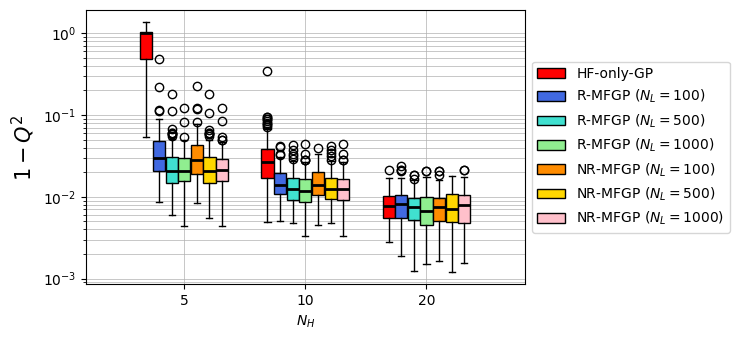

In [9]:
widths = 0.1
little_offset= 0.025
medianprops = dict(color='black', linewidth=2)
with open(path_metrics, "rb") as f:
    All_Metrics = pickle.load(f)
    l_mf = All_Metrics["MF rec"]["error"]     
    l_hf = All_Metrics["HF only"]["error"]  
    l_mf2 = All_Metrics["MF nrec"]["error"]
l_hf = l_hf.tolist()
positions = np.arange(numH)
colors = ["red", "royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
#colors = ["red", "royalblue", "turquoise", 'lightgreen', 'purple', 'violet', 'pink']
labels = ["HF-only-GP"] + [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
fig, ax = plt.subplots(figsize=(10, 3.5))
n_models = 1 + 2*numL
total_width = n_models * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
b_hf = ax.boxplot(
    l_hf, positions=positions + offsets[0], widths=widths,
    patch_artist=True, boxprops=dict(facecolor=colors[0]),
    medianprops=medianprops)
bps = [b_hf]
for i in range(numL):
    li_mf = (l_mf[i, :, :]).tolist()
    b = ax.boxplot(
        li_mf, positions=positions + offsets[i + 1], widths=widths,
        patch_artist=True, boxprops=dict(facecolor=colors[i + 1]), medianprops=medianprops)
    bps.append(b)
start = 1 + numL
for i in range(numL):
    li_mf2 = l_mf2[i, :, :].tolist()
    b = ax.boxplot(
        li_mf2, positions=positions + offsets[start + i], widths=widths, patch_artist=True,
        boxprops=dict(facecolor=colors[start + i]), medianprops=medianprops
    )
    bps.append(b)
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("$1 - Q^2$", fontsize=15)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir+"/Sine_Errors.pdf", format="pdf")
plt.show()

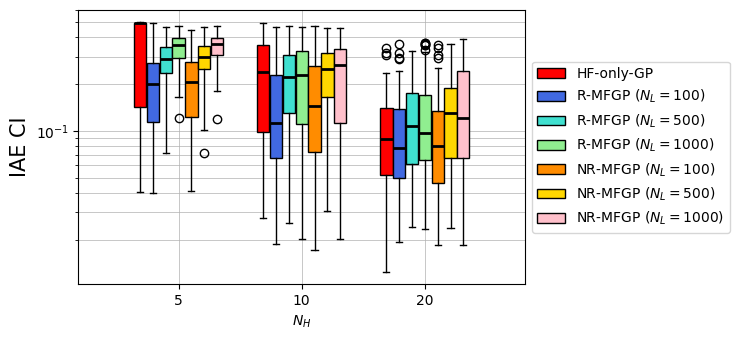

In [10]:
widths = 0.1
little_offset= 0.025
medianprops = dict(color='black', linewidth=2)
with open(path_metrics, "rb") as f:
    All_Metrics = pickle.load(f)
    l_mf = All_Metrics["MF rec"]["IAE_CI"]     
    l_hf = All_Metrics["HF only"]["IAE_CI"]  
    l_mf2 = All_Metrics["MF nrec"]["IAE_CI"]
l_hf = l_hf.tolist()
positions = np.arange(numH)
colors = ["red", "royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
#colors = ["red", "royalblue", "turquoise", 'lightgreen', 'purple', 'violet', 'pink']
labels = ["HF-only-GP"] + [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
fig, ax = plt.subplots(figsize=(10, 3.5))
n_models = 1 + 2*numL
total_width = n_models * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
b_hf = ax.boxplot(
    l_hf, positions=positions + offsets[0], widths=widths,
    patch_artist=True, boxprops=dict(facecolor=colors[0]),
    medianprops=medianprops)
bps = [b_hf]
for i in range(numL):
    li_mf = (l_mf[i, :, :]).tolist()
    b = ax.boxplot(
        li_mf, positions=positions + offsets[i + 1], widths=widths,
        patch_artist=True, boxprops=dict(facecolor=colors[i + 1]), medianprops=medianprops)
    bps.append(b)
start = 1 + numL
for i in range(numL):
    li_mf2 = l_mf2[i, :, :].tolist()
    b = ax.boxplot(
        li_mf2, positions=positions + offsets[start + i], widths=widths, patch_artist=True,
        boxprops=dict(facecolor=colors[start + i]), medianprops=medianprops
    )
    bps.append(b)
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("IAE CI", fontsize=15)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir+"/Sine_IAE_CI.pdf", format="pdf")
plt.show()

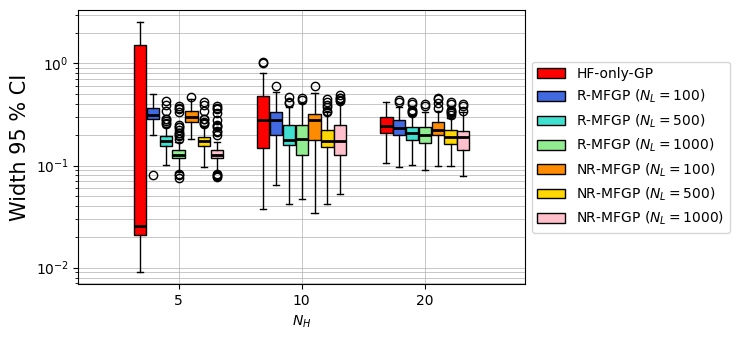

In [11]:
widths = 0.1
little_offset= 0.025
medianprops = dict(color='black', linewidth=2)
with open(path_metrics, "rb") as f:
    All_Metrics = pickle.load(f)
    l_mf = All_Metrics["MF rec"]["WidthCI"]     
    l_hf = All_Metrics["HF only"]["WidthCI"]  
    l_mf2 = All_Metrics["MF nrec"]["WidthCI"]
l_hf = l_hf.tolist()
positions = np.arange(numH)
colors = ["red", "royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
#colors = ["red", "royalblue", "turquoise", 'lightgreen', 'purple', 'violet', 'pink']
labels = ["HF-only-GP"] + [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
fig, ax = plt.subplots(figsize=(10, 3.5))
n_models = 1 + 2*numL
total_width = n_models * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
b_hf = ax.boxplot(
    l_hf, positions=positions + offsets[0], widths=widths,
    patch_artist=True, boxprops=dict(facecolor=colors[0]),
    medianprops=medianprops)
bps = [b_hf]
for i in range(numL):
    li_mf = (l_mf[i, :, :]).tolist()
    b = ax.boxplot(
        li_mf, positions=positions + offsets[i + 1], widths=widths,
        patch_artist=True, boxprops=dict(facecolor=colors[i + 1]), medianprops=medianprops)
    bps.append(b)
start = 1 + numL
for i in range(numL):
    li_mf2 = l_mf2[i, :, :].tolist()
    b = ax.boxplot(
        li_mf2, positions=positions + offsets[start + i], widths=widths, patch_artist=True,
        boxprops=dict(facecolor=colors[start + i]), medianprops=medianprops
    )
    bps.append(b)
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("Width 95 % CI", fontsize=15)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir+"/Sine_width_CI.pdf", format="pdf")
plt.show()

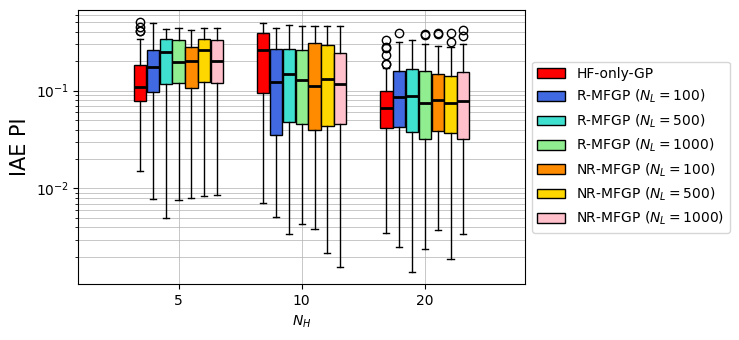

In [12]:
widths = 0.1
little_offset= 0.025
medianprops = dict(color='black', linewidth=2)
with open(path_metrics, "rb") as f:
    All_Metrics = pickle.load(f)
    l_mf = All_Metrics["MF rec"]["IAE_PI"]     
    l_hf = All_Metrics["HF only"]["IAE_PI"]  
    l_mf2 = All_Metrics["MF nrec"]["IAE_PI"]
l_hf = l_hf.tolist()
positions = np.arange(numH)
colors = ["red", "royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
#colors = ["red", "royalblue", "turquoise", 'lightgreen', 'purple', 'violet', 'pink']
labels = ["HF-only-GP"] + [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
fig, ax = plt.subplots(figsize=(10, 3.5))
n_models = 1 + 2*numL
total_width = n_models * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
b_hf = ax.boxplot(
    l_hf, positions=positions + offsets[0], widths=widths,
    patch_artist=True, boxprops=dict(facecolor=colors[0]),
    medianprops=medianprops)
bps = [b_hf]
for i in range(numL):
    li_mf = (l_mf[i, :, :]).tolist()
    b = ax.boxplot(
        li_mf, positions=positions + offsets[i + 1], widths=widths,
        patch_artist=True, boxprops=dict(facecolor=colors[i + 1]), medianprops=medianprops)
    bps.append(b)
start = 1 + numL
for i in range(numL):
    li_mf2 = l_mf2[i, :, :].tolist()
    b = ax.boxplot(
        li_mf2, positions=positions + offsets[start + i], widths=widths, patch_artist=True,
        boxprops=dict(facecolor=colors[start + i]), medianprops=medianprops)
    bps.append(b)
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("IAE PI", fontsize=15)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir+"/Sine_IAE_PI.pdf", format="pdf")
plt.show()

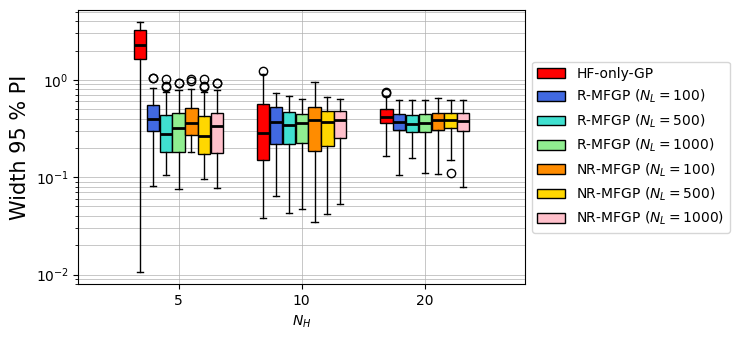

In [13]:
widths = 0.1
little_offset= 0.025
medianprops = dict(color='black', linewidth=2)
with open(path_metrics, "rb") as f:
    All_Metrics = pickle.load(f)
    l_mf = All_Metrics["MF rec"]["WidthPI"]     
    l_hf = All_Metrics["HF only"]["WidthPI"]  
    l_mf2 = All_Metrics["MF nrec"]["WidthPI"]
l_hf = l_hf.tolist()
positions = np.arange(numH)
colors = ["red", "royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
#colors = ["red", "royalblue", "turquoise", 'lightgreen', 'purple', 'violet', 'pink']
labels = ["HF-only-GP"] + [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
fig, ax = plt.subplots(figsize=(10, 3.5))
n_models = 1 + 2*numL
total_width = n_models * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
b_hf = ax.boxplot(
    l_hf, positions=positions + offsets[0], widths=widths,
    patch_artist=True, boxprops=dict(facecolor=colors[0]),
    medianprops=medianprops)
bps = [b_hf]
for i in range(numL):
    li_mf = (l_mf[i, :, :]).tolist()
    b = ax.boxplot(
        li_mf, positions=positions + offsets[i + 1], widths=widths,
        patch_artist=True, boxprops=dict(facecolor=colors[i + 1]), medianprops=medianprops)
    bps.append(b)
start = 1 + numL
for i in range(numL):
    li_mf2 = l_mf2[i, :, :].tolist()
    b = ax.boxplot(
        li_mf2, positions=positions + offsets[start + i], widths=widths, patch_artist=True,
        boxprops=dict(facecolor=colors[start + i]), medianprops=medianprops
    )
    bps.append(b)
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("Width 95 % PI", fontsize=15)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir+"/Sine_width_PI.pdf", format="pdf")
plt.show()

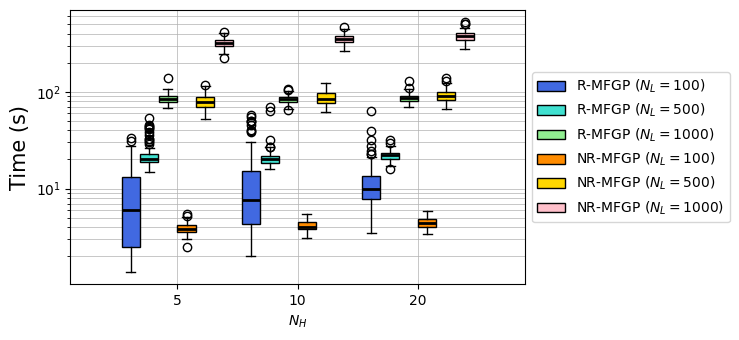

In [14]:
widths = 0.15
little_offset= 0.025
medianprops = dict(color='black', linewidth=2)
with open(path_metrics, "rb") as f:
    All_Metrics = pickle.load(f)
    l_mf = All_Metrics["MF rec"]["Time"]       
    l_mf2 = All_Metrics["MF nrec"]["Time"]
positions = np.arange(numH)
colors = ["royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
#colors = ["royalblue", "turquoise", 'lightgreen','purple', 'violet', 'pink']
labels = [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
fig, ax = plt.subplots(figsize=(10, 3.5))
n_models = 2*numL
total_width = n_models * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
bps = []
for i in range(numL):
    li_mf = (l_mf[i, :, :]).tolist()
    b = ax.boxplot(
        li_mf, positions=positions + offsets[i], widths=widths,
        patch_artist=True, boxprops=dict(facecolor=colors[i]), medianprops=medianprops)
    bps.append(b)
start = numL
for i in range(numL):
    li_mf2 = l_mf2[i, :, :].tolist()
    b = ax.boxplot(
        li_mf2, positions=positions + offsets[start + i], widths=widths, patch_artist=True,
        boxprops=dict(facecolor=colors[start + i]), medianprops=medianprops
    )
    bps.append(b)
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("Time (s)", fontsize=15)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir+"/Sine_times.pdf", format="pdf")
plt.show()

In [15]:
np.array([line.get_ydata()[0] for line in bps[3]["medians"]]) / np.array([line.get_ydata()[0] for line in bps[0]["medians"]])

array([0.64147269, 0.53634862, 0.4433858 ])

In [16]:
np.array([line.get_ydata()[0] for line in bps[4]["medians"]]) / np.array([line.get_ydata()[0] for line in bps[1]["medians"]])

array([3.91253417, 4.19863624, 4.09455807])

In [17]:
np.array([line.get_ydata()[0] for line in bps[5]["medians"]]) / np.array([line.get_ydata()[0] for line in bps[2]["medians"]])

array([3.70334656, 4.13254732, 4.37907298])

In [18]:
def check_EM_monotonicity(EM_traces, listN_L, listN_H, rel_tol=1e-8, errors=None,
                          plot=True, max_plots=20, verbose=True):
    """ Checks, for every saved recursive MF-GP (EM), whether the sequence of
        log-likelihood values stored in MF_gp.log_lik_values is non-decreasing.
    Args:
        EM_traces (dict): EM_traces[(i, j, k)] = MF_gp.log_lik_values, as saved in Sine_metrics.pkl.
        listN_L, listN_H (lists): LF / HF sample sizes, indexed by i and j.
        rel_tol (float): A decrease l_{t+1} - l_t < -rel_tol * max(1, |l_t|) is counted as a violation;
                         smaller decreases are reported separately as numerical noise.
        errors (None or array (numL, numH, num_rep)): Optional, e.g. error_vals_mf (1 - Q2), to compare
                         the accuracy of the runs with and without violations.
        plot (bool): Plots the log-likelihood trajectories of (up to max_plots) runs with violations.
        verbose (bool): Prints the summary tables.
    Returns:
        report (list of dict): One entry per run with at least one violation (or non-finite value).
        summary (dict): summary[(i, j)] = (number of runs, number of runs with violations).
    """
    report, summary = [], {}
    n_runs, n_noise_only, n_missing = 0, 0, 0
    for (i, j, k), ll in sorted(EM_traces.items()):
        n_tot, n_vio = summary.get((i, j), (0, 0))
        if ll is None or len(ll) < 2:
            # Simplified case (no EM) or attribute not saved
            n_missing += 1
            continue
        n_runs += 1
        ll = np.asarray(ll, dtype=float)
        diffs = np.diff(ll)
        scale = np.maximum(1., np.abs(ll[:-1]))
        nonfinite = not np.all(np.isfinite(ll))
        strict_dec = diffs < 0
        vio = diffs < -rel_tol * scale
        if nonfinite or vio.any():
            n_vio += 1
            idx = np.where(vio)[0]
            report.append({
                'key': (i, j, k), 'N_L': listN_L[i], 'N_H': listN_H[j],
                'n_iter': len(ll) - 1,
                'iterations': (idx + 1).tolist(),             # t such that l_t < l_{t-1}
                'max_abs_drop': float(-diffs[idx].min()) if idx.size else np.nan,
                'max_rel_drop': float((-diffs[idx] / scale[idx]).max()) if idx.size else np.nan,
                'total_gain': float(ll[-1] - ll[0]),
                'nonfinite': nonfinite,
                'll': ll})
        elif strict_dec.any():
            n_noise_only += 1
        summary[(i, j)] = (n_tot + 1, n_vio)
    if verbose:
        print(f"Runs checked: {n_runs}  (skipped, no EM trace: {n_missing})")
        print(f"Runs with violations (rel_tol={rel_tol:g}): {len(report)}")
        print(f"{'N_L':>6} {'N_H':>6} {'runs':>6} {'violations':>6}")
        for (i, j), (n_tot, n_vio) in sorted(summary.items()):
            print(f"{listN_L[i]:>6} {listN_H[j]:>6} {n_tot:>6} {n_vio:>6}")
        if report:
            print(f"\n{'(i,j,k)':>12} {'N_L':>5} {'N_H':>5} {'iters':>6} {'drops at t':>16} "
                  f"{'max abs drop':>13} {'max rel drop':>13} {'total gain':>11}")
            for r in report:
                its = ','.join(map(str, r['iterations'])) if r['iterations'] else '-'
                flag = '  (non-finite)' if r['nonfinite'] else ''
                print(f"{str(r['key']):>12} {r['N_L']:>5} {r['N_H']:>5} {r['n_iter']:>6} {its:>16} "
                      f"{r['max_abs_drop']:>13.3e} {r['max_rel_drop']:>13.3e} {r['total_gain']:>11.3e}{flag}")
        if errors is not None and report:
            bad = np.zeros(errors.shape, dtype=bool)
            for r in report:
                bad[r['key']] = True
            print("\nAccuracy (median of the given metric), runs with vs without violations:")
            for (i, j) in sorted(summary):
                e_bad, e_ok = errors[i, j][bad[i, j]], errors[i, j][~bad[i, j]]
                if e_bad.size:
                    print(f"  N_L={listN_L[i]:>4}, N_H={listN_H[j]:>3}: "
                          f"with = {np.median(e_bad):.3e} (n={e_bad.size}), "
                          f"without = {np.median(e_ok):.3e} (n={e_ok.size})")
    if plot and report:
        n = min(len(report), max_plots)
        ncols = min(4, n)
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(3.2*ncols, 2.6*nrows), squeeze=False)
        for ax, r in zip(axes.ravel(), report[:n]):
            ll = r['ll']
            ax.plot(np.arange(len(ll)), ll, 'o-', ms=3)
            for t in r['iterations']:
                ax.plot([t-1, t], ll[t-1:t+1], 'r-', lw=2)
            ax.set_title(f"{r['key']}  N_L={r['N_L']}, N_H={r['N_H']}", fontsize=8)
            ax.set_xlabel('EM iteration', fontsize=8)
            ax.tick_params(labelsize=7)
            ax.grid()
        for ax in axes.ravel()[n:]:
            ax.axis('off')
        fig.suptitle('Log-likelihood along EM iterations (decreases in red)', fontsize=10)
        plt.tight_layout()
        plt.show()
    return report, summary

In [19]:
report, summary = check_EM_monotonicity(EM_traces, listN_L, listN_H, rel_tol=1e-8, errors=error_vals_mf, plot=True)

Runs checked: 900  (skipped, no EM trace: 0)
Runs with violations (rel_tol=1e-08): 0
   N_L    N_H   runs violations
   100      5    100      0
   100     10    100      0
   100     20    100      0
   500      5    100      0
   500     10    100      0
   500     20    100      0
  1000      5    100      0
  1000     10    100      0
  1000     20    100      0


## HF noise variance estimation

In [20]:
def check_noise_estimation(NV_hf, NV_mf, NV_ko, noise_true, listN_L, listN_H, factor=2., collapse=1e-2, plot=True):
    """ Compares the HF noise variance estimated by each model with the true value noise_true.
    Args:
        NV_hf ((numH, num_rep) array): Estimated HF noise variance, HF-only GP.
        NV_mf, NV_ko ((numL, numH, num_rep) arrays): Estimated HF noise variance, R-MFGP and NR-MFGP.
        noise_true (float): True HF noise variance (noise_H).
        listN_L, listN_H (lists): LF / HF sample sizes, indexed by i and j.
        factor (float): A run is under- (over-) estimated if r = estimated / true < 1/factor (> factor).
        collapse (float): A run is 'collapsed' if r < collapse (noise shrunk towards 0: the model interpolates the noisy data).
        plot (bool): Boxplots of the ratio r per configuration (log scale).
    Returns:
        summary (dict): summary[(model, N_L, N_H)] = dict(median, q10, q90 of r, fractions under / over / collapsed).
        ratios (dict): ratios[(model, N_L, N_H)] = array of r over the replications.
    """
    models = ['HF-only-GP', 'R-MFGP', 'NR-MFGP']
    keys = [(m, N_L, N_H) for m in models for N_H in listN_H for N_L in ([None] if m == 'HF-only-GP' else listN_L)]
    ratios = {}
    for j, N_H in enumerate(listN_H):
        ratios[('HF-only-GP', None, N_H)] = NV_hf[j] / noise_true
        for i, N_L in enumerate(listN_L):
            ratios[('R-MFGP', N_L, N_H)] = NV_mf[i, j] / noise_true
            ratios[('NR-MFGP', N_L, N_H)] = NV_ko[i, j] / noise_true
    summary = {key: {'median': np.median(r), 'q10': np.quantile(r, 0.1), 'q90': np.quantile(r, 0.9),
                     'frac_under': np.mean(r < 1 / factor), 'frac_over': np.mean(r > factor),
                     'frac_collapsed': np.mean(r < collapse)}
               for key, r in ratios.items()}
    print(f"r = estimated / true HF noise variance (true = {noise_true:g}) ; "
          f"under: r < 1/{factor:g}, over: r > {factor:g}, collapsed: r < {collapse:g}\n")
    print(f"{'model':>11} {'N_L':>5} {'N_H':>5} {'median r':>9} {'r q10':>8} {'r q90':>8} "
          f"{'% under':>8} {'% over':>7} {'% collapsed':>12}")
    for n, key in enumerate(keys):
        if n > 0 and key[0] != keys[n-1][0]:
            print()
        model, N_L, N_H = key
        s = summary[key]
        print(f"{model:>11} {('-' if N_L is None else N_L):>5} {N_H:>5} {s['median']:>9.3f} {s['q10']:>8.3f} {s['q90']:>8.3f} "
              f"{100*s['frac_under']:>7.0f}% {100*s['frac_over']:>6.0f}% {100*s['frac_collapsed']:>11.0f}%")
    if plot:
        widths, little_offset = 0.1, 0.025
        medianprops = dict(color='black', linewidth=2)
        colors = ["red", "royalblue", "turquoise", 'lightgreen', 'darkorange', 'gold', 'pink']
        labels = ["HF-only-GP"] + [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"NR-MFGP ($N_L={N_L}$)" for N_L in listN_L]
        groups = [[ratios[('HF-only-GP', None, N_H)] for N_H in listN_H]] \
               + [[ratios[('R-MFGP', N_L, N_H)] for N_H in listN_H] for N_L in listN_L] \
               + [[ratios[('NR-MFGP', N_L, N_H)] for N_H in listN_H] for N_L in listN_L]
        positions = np.arange(len(listN_H))
        n_models = len(groups)
        total_width = n_models * widths + little_offset
        offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, n_models)
        fig, ax = plt.subplots(figsize=(10, 3.5))
        bps = [ax.boxplot(g, positions=positions + offsets[m], widths=widths, patch_artist=True,
                          boxprops=dict(facecolor=colors[m]), medianprops=medianprops)
               for m, g in enumerate(groups)]
        ax.axhline(1., color='black', linestyle='--', linewidth=1)
        ax.axhspan(1 / factor, factor, color='grey', alpha=0.15, zorder=0)
        ax.set_yscale("log")
        ax.set_xticks(positions)
        ax.set_xticklabels(listN_H)
        ax.set_xlabel("$N_H$")
        ax.set_ylabel(r"$\hat\sigma^2_{\varepsilon,H} / \sigma^2_{\varepsilon,H}$", fontsize=15)
        ax.grid(which="both", linestyle="-", linewidth=0.5)
        ax.legend([bp["boxes"][0] for bp in bps], labels, loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
        plt.tight_layout(rect=[0, 0, 0.75, 1])
        plt.show()
    return summary, ratios

r = estimated / true HF noise variance (true = 0.01) ; under: r < 1/2, over: r > 2, collapsed: r < 0.01

      model   N_L   N_H  median r    r q10    r q90  % under  % over  % collapsed
 HF-only-GP     -     5    28.362    0.000   82.683      34%     65%          34%
 HF-only-GP     -    10     0.028    0.000    1.687      72%      8%          46%
 HF-only-GP     -    20     0.733    0.356    1.570      20%      3%           0%

     R-MFGP   100     5     0.188    0.000    2.304      58%     13%          33%
     R-MFGP   500     5     0.245    0.000    2.174      59%     11%          38%
     R-MFGP  1000     5     0.518    0.000    2.260      48%     13%          29%
     R-MFGP   100    10     0.307    0.000    1.438      59%      2%          33%
     R-MFGP   500    10     0.358    0.000    1.531      56%      4%          29%
     R-MFGP  1000    10     0.387    0.000    1.565      56%      3%          27%
     R-MFGP   100    20     0.555    0.000    1.258      43%      0%      

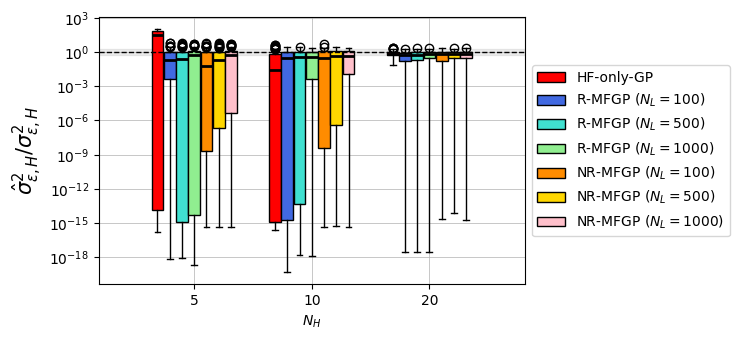

In [21]:
summary_nv, ratios_nv = check_noise_estimation(NV_hf, NV_mf, NV_ko, noise_H, listN_L, listN_H, factor=2.)

In [22]:
def compute_nesting_distance(listN_L, listN_H, num_rep, D, runs_dir=None, print_all=True, verbose=True):
    """ Nesting distance between the LF and HF designs of every configuration (N_L, N_H, k):
            T = max_{x_H in X_H} min_{x_L in X_L} ||x_H - x_L||_2 
            (directed Hausdorff distance from X_H to X_L, T = 0 if X_H is included in X_L).
    Args:
        listN_L, listN_H (lists): LF / HF sample sizes, indexed by i and j.
        num_rep (int): Number of replications k.
        D (int): Input dimension.
        runs_dir (None or str): If given, X_L and X_H are read from the saved replication files ('Data').
                         Otherwise they are regenerated with generate_data(k) (same draws as run_replication(k)).
        print_all (bool): Prints T for every replication k and every (N_L, N_H).
        verbose (bool): Prints the summary table (mean, median, std, min, max over the replications).
    Returns:
        T_nest ((numL, numH, num_rep) array): T_nest[i, j, k], same indexing as error_vals_mf.
        summary (dict): summary[(N_L, N_H)] = dict(mean, median, std, min, max of T over k).
    """
    numL, numH = len(listN_L), len(listN_H)
    T_nest = np.zeros((numL, numH, num_rep))
    for k in range(num_rep):
        if runs_dir is not None:
            with open(rep_path(k), 'rb') as f:
                Res_k = pickle.load(f)
        else:
            data = generate_data(k)
        for j in range(numH):
            for i in range(numL):
                if runs_dir is None:
                    X_H, X_L = data[('H', j)][0], data[('L', i, j)][0]
                else:
                    X_L, _, X_H, _ = Res_k[(i, j, k)]['Data']
                diff = X_H[:, None, :] - X_L[None, :, :]               # (N_H, N_L, D)
                d_min = np.sqrt(np.sum(diff**2, axis=-1)).min(axis=1)  # min over x_L, for each x_H
                T_nest[i, j, k] = d_min.max()                          # max over x_H
    configs = [(i, j) for j in range(numH) for i in range(numL)]
    if print_all:
        header = ''.join(f"{f'({listN_L[i]},{listN_H[j]})':>12}" for i, j in configs)
        print(f"T for each replication, columns = (N_L, N_H)\n{'k':>4}{header}")
        for k in range(num_rep):
            print(f"{k:>4}" + ''.join(f"{T_nest[i, j, k]:>12.4f}" for i, j in configs))
        print()
    summary = {}
    for i, j in configs:
        t = T_nest[i, j]
        summary[(listN_L[i], listN_H[j])] = dict(mean=t.mean(), median=np.median(t), std=t.std(ddof=1),
                                                 min=t.min(), max=t.max())
    if verbose:
        print(f"Summary over {num_rep} replications")
        print(f"{'N_L':>6} {'N_H':>6} {'mean':>9} {'median':>9} {'std':>9} {'min':>9} {'max':>9}")
        for (N_L, N_H), s in summary.items():
            print(f"{N_L:>6} {N_H:>6} {s['mean']:>9.4f} {s['median']:>9.4f} {s['std']:>9.4f} "
                  f"{s['min']:>9.4f} {s['max']:>9.4f}")
    return T_nest, summary
#T_nest, summary_nest = compute_nesting_distance(listN_L, listN_H, num_rep, D)
T_nest, summary_nest = compute_nesting_distance(listN_L, listN_H, num_rep, D, runs_dir=runs_dir, print_all=False)  # from the saved designs

Summary over 100 replications
   N_L    N_H      mean    median       std       min       max
   100      5    0.0110    0.0107    0.0032    0.0037    0.0189
   500      5    0.0022    0.0021    0.0006    0.0009    0.0037
  1000      5    0.0011    0.0011    0.0003    0.0003    0.0018
   100     10    0.0122    0.0121    0.0026    0.0069    0.0178
   500     10    0.0026    0.0026    0.0006    0.0007    0.0038
  1000     10    0.0013    0.0013    0.0002    0.0006    0.0018
   100     20    0.0139    0.0138    0.0019    0.0103    0.0179
   500     20    0.0027    0.0027    0.0004    0.0016    0.0039
  1000     20    0.0014    0.0014    0.0002    0.0009    0.0018


  N_L   N_H  median   q10   q90  % cap
  100     5      64    15   200    31%
  500     5      17     8   133     9%
 1000     5      10     6    56     4%
  100    10      28    16   159     8%
  500    10      10     8    19     2%
 1000    10       7     6    11     0%
  100    20      26    17    47     0%
  500    20      10     8    13     0%
 1000    20       7     6    10     0%


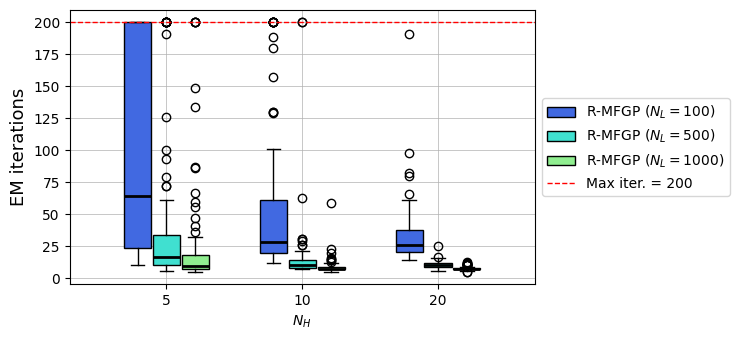

In [23]:
offset = 1   # log_lik_values contains the initial value (consistent with check_EM_monotonicity)
n_iter = np.full((numL, numH, num_rep), np.nan)
for (i, j, k), ll in EM_traces.items():
    n_iter[i, j, k] = len(ll) - offset
print(f"{'N_L':>5} {'N_H':>5} {'median':>7} {'q10':>5} {'q90':>5} {'% cap':>6}")
for j, N_H in enumerate(listN_H):
    for i, N_L in enumerate(listN_L):
        it = n_iter[i, j]
        print(f"{N_L:>5} {N_H:>5} {np.median(it):>7.0f} {np.quantile(it, .1):>5.0f} {np.quantile(it, .9):>5.0f} "
              f"{100 * np.mean(it >= EM_iter):>5.0f}%")

widths, little_offset = 0.2, 0.025
colors = ["royalblue", "turquoise", 'lightgreen']
positions = np.arange(numH)
total_width = numL * widths + little_offset
offsets = np.linspace(-total_width/2 + widths/2, total_width/2 - widths/2, numL)
fig, ax = plt.subplots(figsize=(10, 3.5))
bps = [ax.boxplot(n_iter[i].tolist(), positions=positions + offsets[i], widths=widths, patch_artist=True,
                  boxprops=dict(facecolor=colors[i]), medianprops=dict(color='black', linewidth=2))
       for i in range(numL)]
ax.axhline(EM_iter, color='red', ls='--', lw=1)
ax.set_xticks(positions)
ax.set_xticklabels(listN_H)
ax.set_xlabel("$N_H$")
ax.set_ylabel("EM iterations", fontsize=13)
ax.grid(which="both", linestyle="-", linewidth=0.5)
ax.legend([bp["boxes"][0] for bp in bps] + [ax.lines[-1]],
          [f"R-MFGP ($N_L={N_L}$)" for N_L in listN_L] + [f"Max iter. = {EM_iter}"],
          loc="center left", fontsize=10, bbox_to_anchor=(1, 0.5))
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.savefig(plot_dir + "/Sine_EM_iterations.pdf", format="pdf")
plt.show()

In [24]:
# EM iterations and time split (LF fit / EM) of the R-MFGP, per configuration (N_L, N_H)
offset = 1   # log_lik_values contains the initial log-likelihood (before the first EM iteration)
n_iter_EM = np.zeros((numL, numH, num_rep))
t_LF = np.zeros((numL, numH, num_rep))
t_EM = np.zeros((numL, numH, num_rep))
for k in tqdm(range(num_rep), desc='EM iterations and time split'):
    with open(rep_path(k), 'rb') as f:
        Res_k = pickle.load(f)   # one replication in memory at a time
    for j in range(numH):
        for i in range(numL):
            r = Res_k[(i, j, k)]
            if 'Time_split_rec' not in r:
                raise KeyError("'Time_split_rec' not found")
            n_iter_EM[i, j, k] = len(r['Class'][0].log_lik_values) - offset
            t_LF[i, j, k], t_EM[i, j, k] = r['Time_split_rec']

def med_iqr(x, fmt=".1f"):
    q1, med, q3 = np.quantile(x, [0.25, 0.5, 0.75])
    return f"{med:{fmt}} [{q1:{fmt}}, {q3:{fmt}}]"

print(f"{'N_L':>5} {'N_H':>5} {'LF fit (s)':>20} {'EM (s)':>20} {'EM iter.':>22} {'% cap':>6} {'share LF':>9}")
for j, N_H in enumerate(listN_H):
    for i, N_L in enumerate(listN_L):
        share = np.median(t_LF[i, j] / (t_LF[i, j] + t_EM[i, j]))
        print(f"{N_L:>5} {N_H:>5} {med_iqr(t_LF[i, j]):>20} {med_iqr(t_EM[i, j]):>20} "
              f"{med_iqr(n_iter_EM[i, j], '.0f'):>22} {100 * np.mean(n_iter_EM[i, j] >= EM_iter):>5.0f}% "
              f"{100 * share:>8.0f}%")

EM iterations and time split: 100%|██████████| 100/100 [00:04<00:00, 23.83it/s]

  N_L   N_H           LF fit (s)               EM (s)               EM iter.  % cap  share LF
  100     5       0.7 [0.6, 0.7]      5.4 [1.9, 12.7]           64 [24, 200]    31%       11%
  500     5    18.2 [16.9, 19.5]       1.3 [0.7, 4.5]            17 [10, 34]     9%       94%
 1000     5    81.9 [77.3, 86.5]       0.8 [0.5, 1.7]             10 [7, 18]     4%       99%
  100    10       0.6 [0.6, 0.7]      6.9 [3.6, 14.7]            28 [20, 61]     8%        9%
  500    10    17.7 [16.5, 19.0]       2.1 [1.5, 3.1]             10 [8, 14]     2%       89%
 1000    10    83.2 [77.3, 87.4]       1.6 [1.1, 2.3]               7 [7, 9]     0%       98%
  100    20       0.6 [0.6, 0.7]      9.4 [7.1, 12.7]            26 [21, 38]     0%        6%
  500    20    18.0 [16.5, 19.4]       4.0 [3.1, 4.7]             10 [9, 12]     0%       82%
 1000    20    83.5 [76.5, 88.0]       3.1 [2.5, 3.6]               7 [7, 8]     0%       96%
